# Manuscript figures from the Stage 1 objects

The figures marked in `ScatterPlot_Oct25.ipynb`, made from the final Stage 1 objects. Plot settings are the same as in the original cells. Changes:

- every figure reads the final Stage 1 object for its sample, including four that originally used older objects (`MH104_setseed`, `MH096_setseed_Jun25`, `MH106_setseed_Jun25_filtered`)
- `cell_class_threshold` replaces `predicted_cell_type_threshold` (Fig. 4b)
- colours are set by cell type name from `manual_colors`; they match the original colour lists
- each figure is saved to `FIGURE_DIR` under a name that starts with its figure number

In [1]:
import os, random, numpy as np
SEED = 23
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
random.seed(SEED)
np.random.seed(SEED)

## Parameters

In [ ]:
# Folders and input files: set these before running (papermill parameters)
STAGE1_DIR = "/path/to/stage1_output"  # one subfolder per sample, with <sample>.h5ad
FIGURE_DIR = "/path/to/stage2_output/manuscript_figures"

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
import os

os.makedirs(FIGURE_DIR, exist_ok=True)
sc.settings.figdir = FIGURE_DIR


def load(sample):
    return sc.read_h5ad(os.path.join(STAGE1_DIR, sample, f"{sample}.h5ad"))


def subset(adata, cell_types, key="cell_class_threshold"):
    """Cells of the given types, with colours from manual_colors."""
    sub = adata[adata.obs[key].isin(cell_types)].copy()
    sub.obs[key] = sub.obs[key].astype(str).astype("category")
    missing = [ct for ct in sub.obs[key].cat.categories if ct not in manual_colors]
    assert not missing, f"No colour for {missing}"
    sub.uns[f"{key}_colors"] = [manual_colors[ct] for ct in sub.obs[key].cat.categories]
    print(sub.obs[key].value_counts().to_string())
    return sub

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [4]:
manual_colors = {
    'Acinar': '#ffb500',
    'Acinar_REG':'#17becf',
    'Adipocytes': 'black',
    'B cells':  '#ff7f0e',
    'CAFs_CXCL14':'#FFB0A7',
    'CAFs_MYO': '#FFE5A7', #'#c7c7c7',
    'CAFs_NRT': "#B4584D",
    "CD4 T cells":  '#7d87b9',
    "CD4 Tfh" : "#46487E",
    "CD4 Treg": '#536CC7',
    "CD8 T cells":'#023fa5',
    "CD8 TRM": "#0A295E",
    "DC1": "#888D07",
    "DC2": "#717417", 
    "Ductal": '#00846f',
    "Ductal MUC5B":'#8dd593',
    "Endocrine": '#809693',
    "Endothelial":'#d62728',
    "FDCs":"#DD51AD",
    "FRCs": "#00BFA0",
    "LECs": "#535A06",
    "Malignant cells": '#8c564b',
    "Mast": '#000035',
    "Migratory DCs": "#105354",
    "NK": "#00025E",
    "Neutrophils": '#b903aa',
    "Pericytes": '#d5eae7', #'#c5b0d5',
    "Plasma": '#9cded6',
    "SMCs": '#d5eae7', #'#c5b0d5',
    "Schwann": '#b79762',
    "TAMs_C1QC":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    "Unclassified": "#cccccc",
    "gdT": '#000035', 
    "pDCs":'#1b4400',
    "Tuft": '#9467bd',
    "Other": "#cccccc",
    'Stromal_CCL19':"#BBDA8F"}

## Fig. 1d: MH065_314, broad cell classes

The broad classes come from the cluster annotation (`anno`), as in the original figure.

In [7]:
adata_065_314 = load("MH065_314")
subset_to_broad = {
    #Acinar
    'Acinar': 'Acinar',
    'Acinar_REG':'Acinar',
    'Acinar_REG+': 'Acinar',
    'Acinar REG+': 'Acinar',
    'Adipocytes': 'Adipocytes',
    'B cells':  'B cells',
    'CAFs_CXCL14':'CAFs',
    'CAFs_MYO': 'CAFs',
    'CAFs_NRT': "CAFs",
    "CD4 T cells":  'CD4 T cells',
    "CD4 Tfh" : "CD4 T cells",
    "CD4 Treg": 'CD4 T cells',
    "CD8 T cells":'CD8 T cells',
    "CD8 TRM": "CD8 T cells",
    "T cells": "T cells", #
    "DC1": "DCs",
    "DC2": "DCs", 
    "IPMN" : "Ductal",
    "Ductal": 'Ductal',
    "Ductal MUC5B":'Ductal',
    "Ductal_MUC5B": "Ductal",
    'Ductal REG+':'Ductal',
    "Endocrine": 'Endocrine',
    'Mixed_Acinar_Endocrine': 'Endocrine',
    "Endothelial":'Endothelial',
    "FDCs": "Lymphoid stromal cells",
    "FRCs": "Lymphoid stromal cells",
    "LECs": "Endothelial",
    "Malignant cells": 'PDAC',
    "Mast": 'Mast',
    "Migratory DCs": "DCs",
    "NK": "CD8 T cells",
    "Neutrophils": 'Granulocytes',
    "Pericytes":'Pericytes_vSMCs',
    "Plasma":  'Plasma',
    "SMCs":'Pericytes_vSMCs',
    "vSMCs": 'Pericytes_vSMCs',
    "Schwann": 'Schwann',
    "Neurons": 'Schwann',
    "TAMs_C1QC":'TAMs',
    "TAMs_MHC": "TAMs",
    "TAMs_OLR1":'TAMs',
    "TAMs_SPP1": 'TAMs',
    "Unclassified": "Unassigned",
    "Unassigned" : "Unassigned",
    "gdT": 'CD8 T cells', 
    "pDCs":'DCs',
    "Tuft": 'Tuft',
    'Mixed_Plasma_CAFs_NRT':"CAFs",#
    'Stromal_CCL19':"Lymphoid stromal cells",
    'TAMs_SPP1_OLR1':"TAMs",
}
# Create a new column with mapped values
adata_065_314.obs["broad_cell_class"] = adata_065_314.obs["anno"].astype(str).map(subset_to_broad).fillna("Other")

# Original colour list, in the order of the broad classes
broad_colors = dict(zip(
    ["Acinar", "B cells", "CAFs", "Ductal", "Endocrine", "Endothelial", "Mast", "PDAC",
     "Pericytes_vSMCs", "Plasma", "T cells", "TAMs", "Unassigned"],
    ["#ff7f0e", "#aa40fc", "#d5eae7", "#279e68", "#e377c2", "#d62728", "#ff9896", "#8c564b",
     "#c5b0d5", "#98df8a", "#023fa5", "#17becf", "#cccccc"],
))
adata_065_314.obs["broad_cell_class"] = adata_065_314.obs["broad_cell_class"].astype("category")
categories = list(adata_065_314.obs["broad_cell_class"].cat.categories)
assert set(categories) <= set(broad_colors), f"No colour for {sorted(set(categories) - set(broad_colors))}"
adata_065_314.uns["broad_cell_class_colors"] = [broad_colors[c] for c in categories]

~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


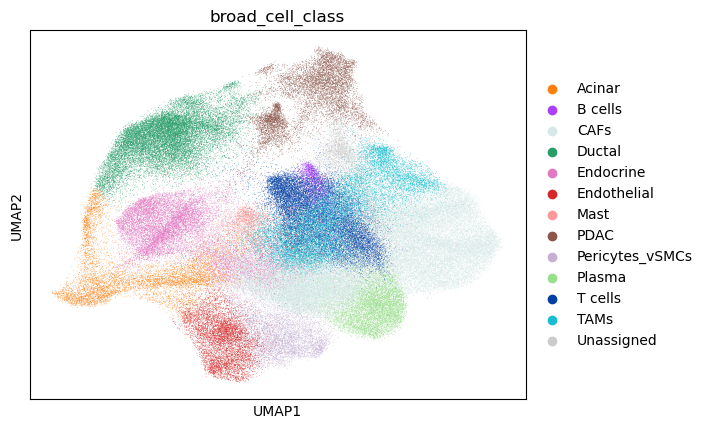

In [8]:
sc.pl.umap(adata_065_314, color=["broad_cell_class"], save="_Fig1d_MH065_314.png")

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


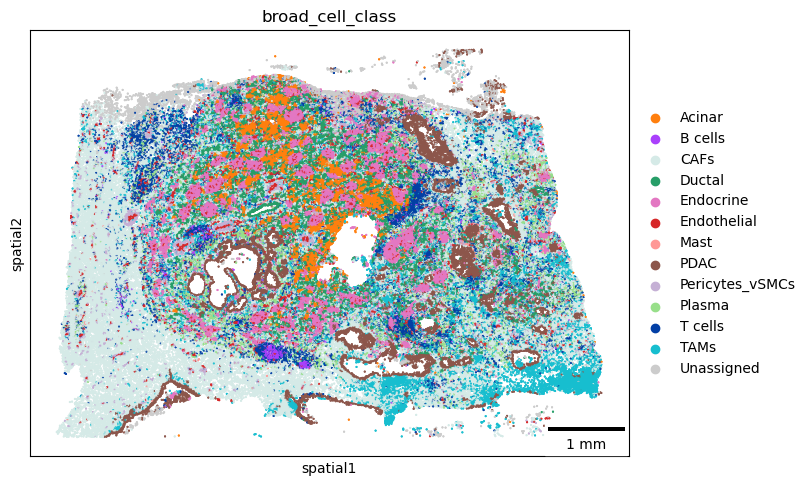

In [9]:
sq.pl.spatial_scatter(
    adata_065_314,
    library_id="spatial",
    shape=None,
    color=[
        "broad_cell_class"
    ],
    wspace=0.4, figsize=(8,8),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    size=1,
    img=False,
    save="Fig1d_MH065_314_scatterplot.png"
)

## Fig. 4b: MH107_480, tumour, TAM and CAF markers

~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


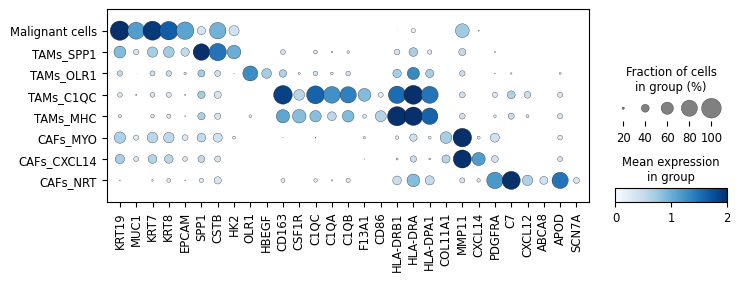

In [10]:
adata_107_480 = load("MH107_480")
order = ['Malignant cells','TAMs_SPP1','TAMs_OLR1','TAMs_C1QC','TAMs_MHC','CAFs_MYO','CAFs_CXCL14','CAFs_NRT']
Tum_CAFs_TAM = adata_107_480[adata_107_480.obs['cell_class_threshold'].isin(order)].copy()
Tum_CAFs_TAM.obs["cell_class_threshold"] = pd.Categorical(
    Tum_CAFs_TAM.obs["cell_class_threshold"].astype(str),
    categories=order,
    ordered=True
)
genes_anno = ['KRT19','MUC1','KRT7','KRT8','EPCAM',
             #'FCGR3B',
              'SPP1','CSTB','HK2','OLR1','HBEGF',
              'CD163','CSF1R','C1QC','C1QA','C1QB','F13A1',
              'CD86','HLA-DRB1','HLA-DRA','HLA-DPA1',
              'COL11A1','MMP11','CXCL14',
              'PDGFRA','C7','CXCL12','ABCA8','APOD','SCN7A'
              ]
sc.pl.dotplot(Tum_CAFs_TAM, var_names = genes_anno , groupby='cell_class_threshold',
             figsize=(8, 2.5), vmax=2.0, vmin = 0, dot_min=0.15, cmap = 'Blues', save='Fig4b_TAMs_CAFs_Tu.pdf',
             dendrogram=False)

## Fig. 4d: tumour, CAF and TAM neighbourhoods

cell_class_threshold
CAFs_MYO           35253
Malignant cells    20629
CAFs_CXCL14        10016
CAFs_NRT            6053
TAMs_C1QC           4778
TAMs_MHC            3227
TAMs_SPP1           2022
TAMs_OLR1           2017


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


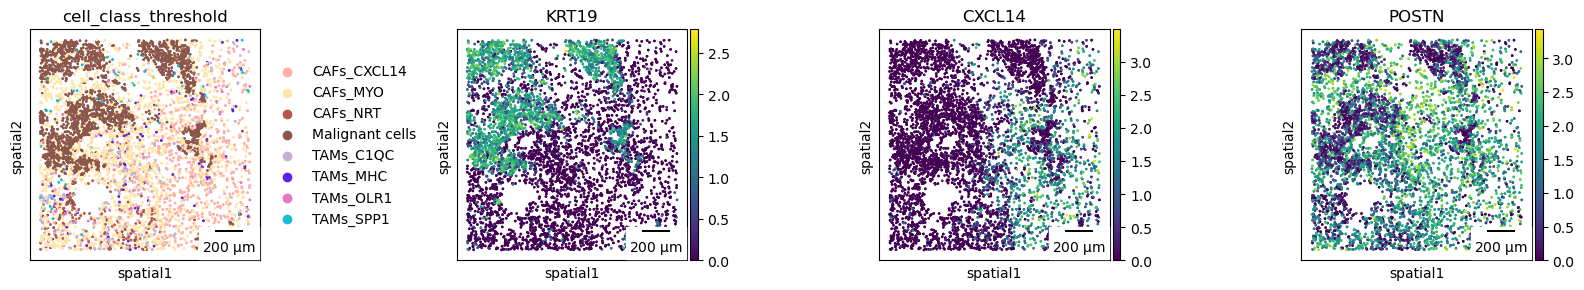

In [11]:
adata_106_480 = load("MH106_480")
toplot = subset(adata_106_480, ['CAFs_CXCL14', 'CAFs_MYO', 'CAFs_NRT','Malignant cells','TAMs_C1QC', 'TAMs_MHC', 'TAMs_OLR1',
       'TAMs_SPP1'])
sq.pl.spatial_scatter(
    toplot, shape=None, color=['cell_class_threshold','KRT19','CXCL14','POSTN'], size=3,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(2800,3000,4300,4500),
    save='Fig4d-1_MH106_480.pdf'
)

cell_class_threshold
CAFs_MYO           37386
Malignant cells    30309
CAFs_CXCL14        11105
TAMs_C1QC           5381
TAMs_MHC            3179
TAMs_SPP1           2492
TAMs_OLR1            988


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


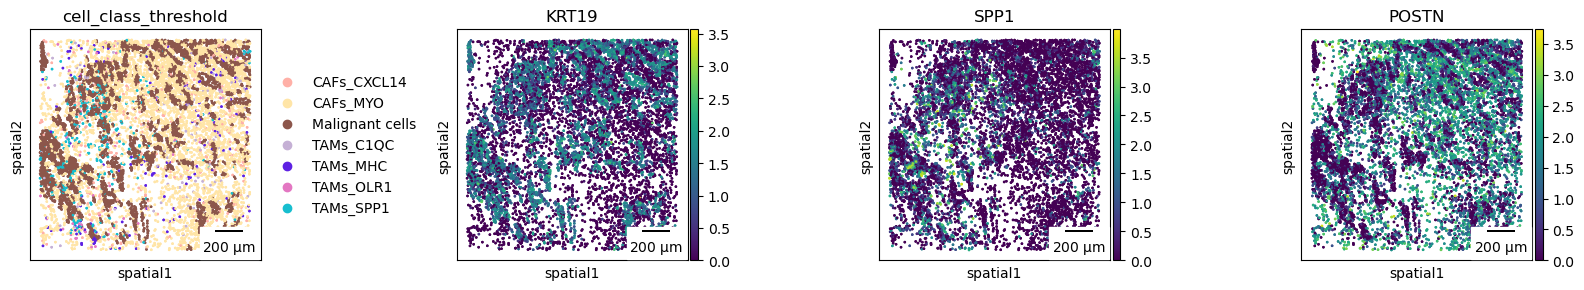

In [12]:
# Originally made from MH104_setseed.h5ad
adata_104_480 = load("MH104_480")
plotting_104 = subset(adata_104_480, ['TAMs_MHC','TAMs_C1QC','Malignant cells',"CAFs_MYO","CAFs_CXCL14", "TAMs_SPP1","TAMs_OLR1"])
sq.pl.spatial_scatter(
    plotting_104, shape=None, color=['cell_class_threshold','KRT19','SPP1','POSTN'], size=3,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(2800, 800, 4300, 2300),
    save='Fig4d-2_MH104_480.pdf'
)

cell_class_threshold
CAFs_MYO           32891
Malignant cells    21536
TAMs_C1QC          12463
TAMs_MHC            6806
TAMs_OLR1           5957
CAFs_CXCL14         2441
TAMs_SPP1            696


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


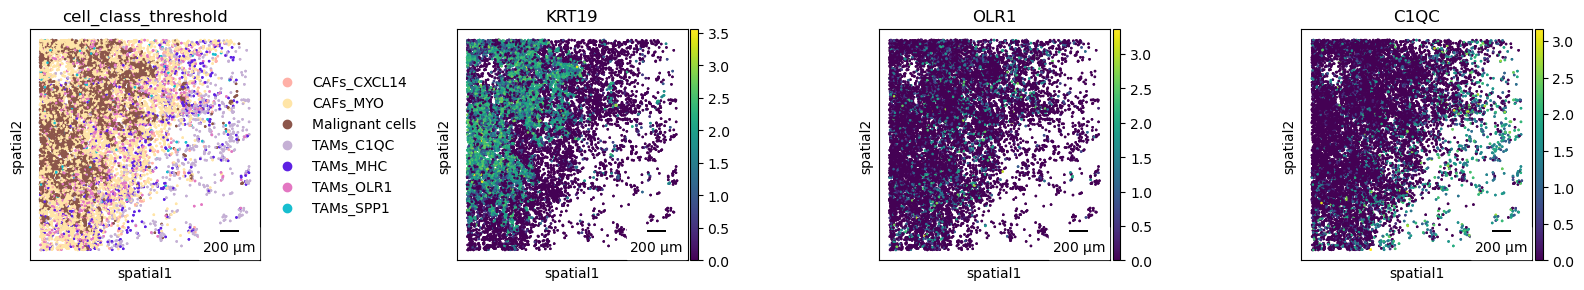

In [13]:
# Originally made from MH096_setseed_Jun25.h5ad
adata_096_480 = load("MH096_480")
plotting_096 = subset(adata_096_480, ['TAMs_OLR1', 'TAMs_SPP1','CAFs_CXCL14','CAFs_MYO','TAMs_MHC','TAMs_C1QC','Malignant cells'])
sq.pl.spatial_scatter(
    plotting_096, shape=None, color=['cell_class_threshold','KRT19','OLR1','C1QC'], size=3,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(4600, 5000, 6800, 7200),
    save='Fig4d-3_MH096_480.pdf'
)

## Fig. 5b: antigen-presenting niches

cell_class_threshold
Plasma           9870
CAFs_NRT         6053
TAMs_C1QC        4778
Mast             4663
CD4 T cells      3767
TAMs_MHC         3227
Migratory DCs    1924
DC2              1732
DC1               766
CD8 T cells       673


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


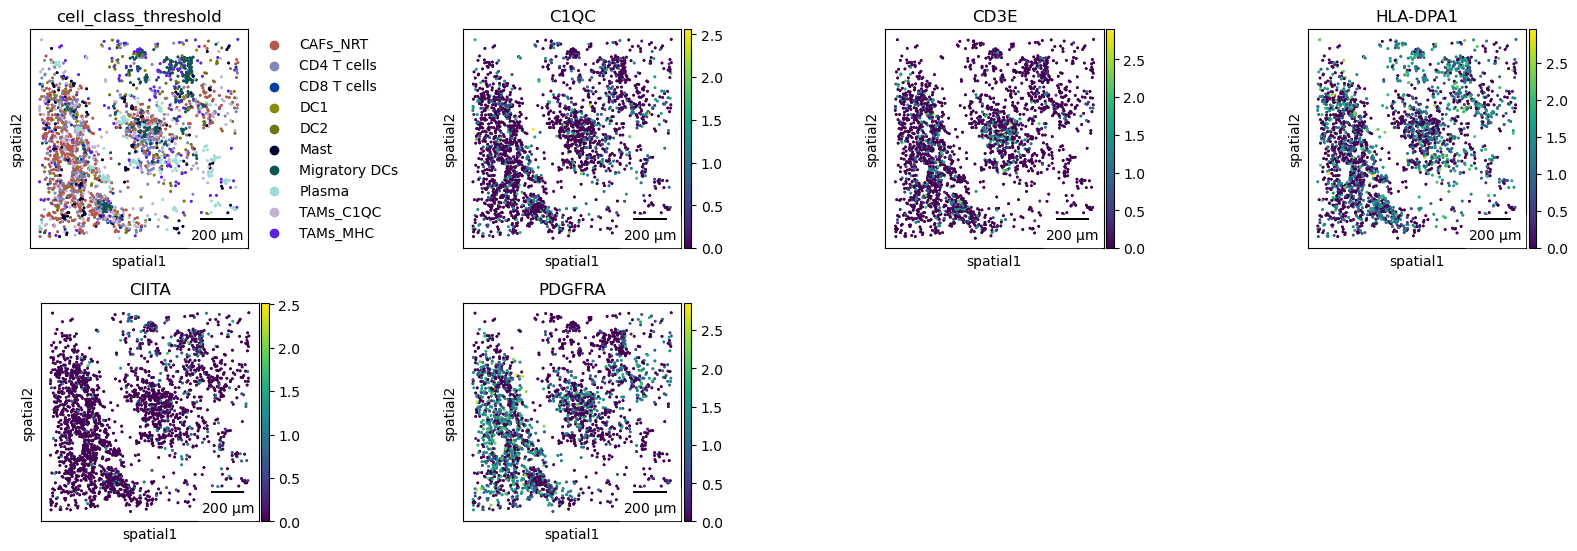

In [15]:
plotting_106 = subset(adata_106_480, ['TAMs_MHC','TAMs_C1QC',"DC1","DC2","Migratory DCs","CD4 T cells","CD8 T cells","CAFs_NRT","Plasma","Mast"])
sq.pl.spatial_scatter(
    plotting_106, shape=None, color=['cell_class_threshold','C1QC','CD3E','HLA-DPA1','CIITA','PDGFRA'], size=4,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(4800, 4800, 6000, 6000),
    save='Fig5b_MH106_480.pdf'
)

cell_class_threshold
Mast             10177
TAMs_C1QC         7501
CAFs_NRT          6972
Plasma            3877
TAMs_MHC          3576
CD4 T cells       2435
CD8 T cells       2087
Migratory DCs      787
DC2                708
DC1                643
Schwann            394


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


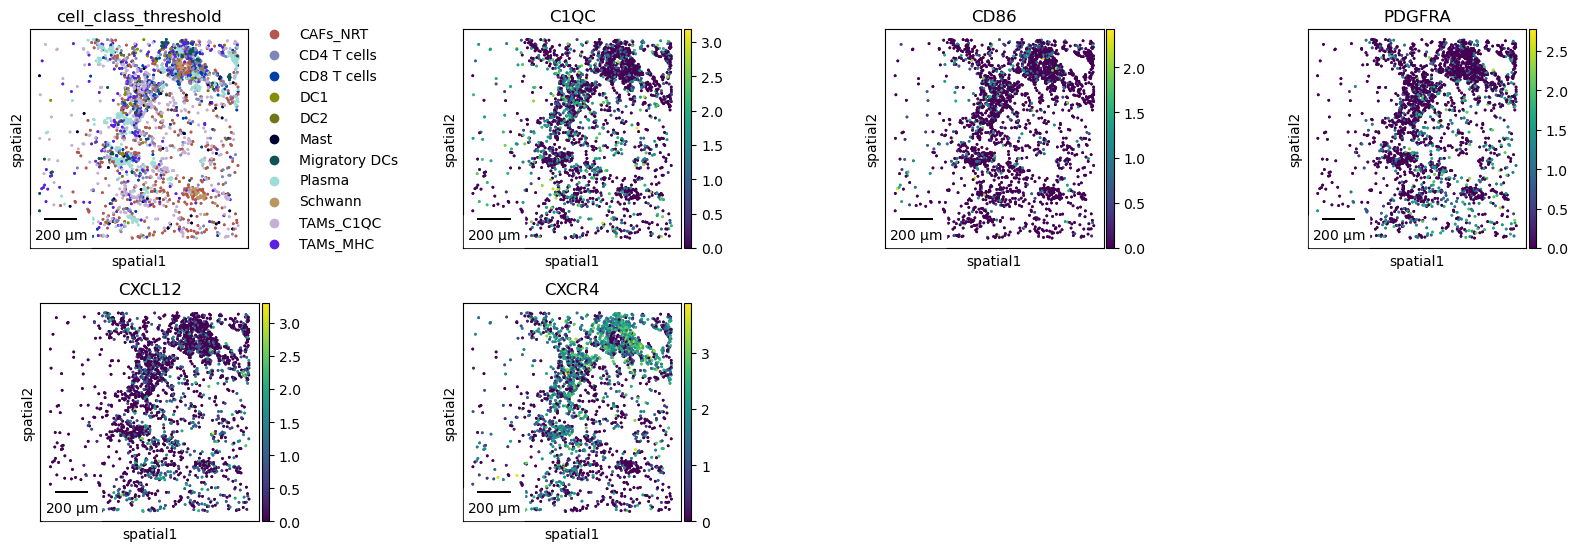

In [17]:
plotting_107_all = subset(adata_107_480, ['TAMs_MHC','TAMs_C1QC',"CD4 T cells","CAFs_NRT","Schwann","Plasma","Mast","Migratory DCs","DC1","DC2","CD8 T cells"])
# Only C1QC, CD86, PDGFRA, CXCL12 and CXCR4 are shown in the figure
sq.pl.spatial_scatter(
    plotting_107_all, shape=None, color=['cell_class_threshold','C1QC','CD86','PDGFRA','CXCL12','CXCR4'],
    size=4,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower left"},
    crop_coord=(8600, 1000, 9800, 2200),
    save='Fig5b-2_MH107_480.pdf'
)

cell_class_threshold
CAFs_NRT         16073
CD4 T cells       6785
TAMs_C1QC         4984
TAMs_MHC          3758
DC2               2564
Migratory DCs     2145
CD8 T cells        912
DC1                805


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


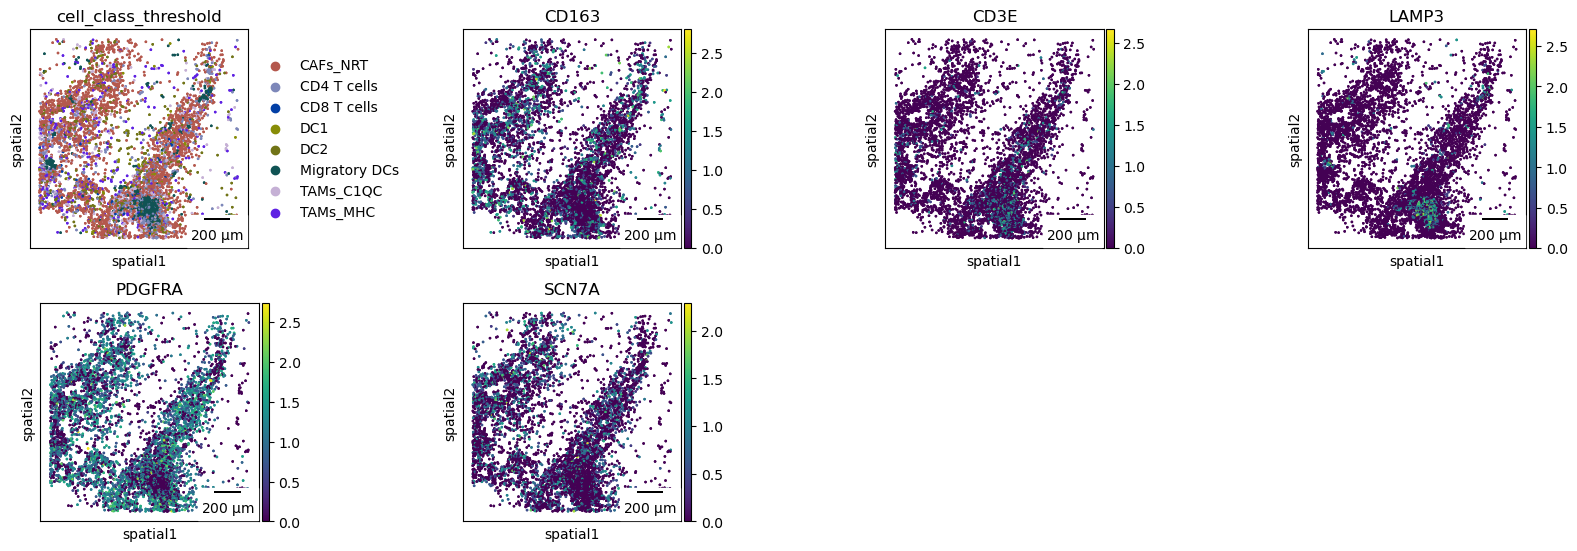

In [19]:
adata_106_314 = load("MH106_314")
plotting_106_314 = subset(adata_106_314, ['TAMs_MHC','TAMs_C1QC',"DC1","DC2","Migratory DCs","CD4 T cells","CD8 T cells","CAFs_NRT"])
# Genes shown in the figure: CD163, CD3E, LAMP3, PDGFRA, SCN7A
sq.pl.spatial_scatter(
    plotting_106_314, shape=None, color=['cell_class_threshold','CD163',"CD3E",'LAMP3','PDGFRA','SCN7A'], size=3,library_id="spatial", figsize=(3, 3),
    wspace=0.6,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(2000, 3500, 3500, 5000),
    save='Fig5b-3_MH106_314.pdf'
)

## Fig. 5e: CXCL12–CXCR4 signalling, MH107_480

~/.local/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = rep_df.groupby(level=0).mean()


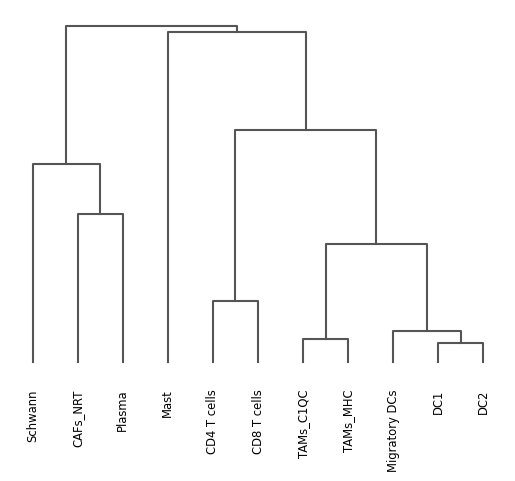

<Axes: >

In [22]:
sc.tl.dendrogram(plotting_107_all, groupby = "cell_class_threshold")
sc.pl.dendrogram(plotting_107_all, groupby = "cell_class_threshold")

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

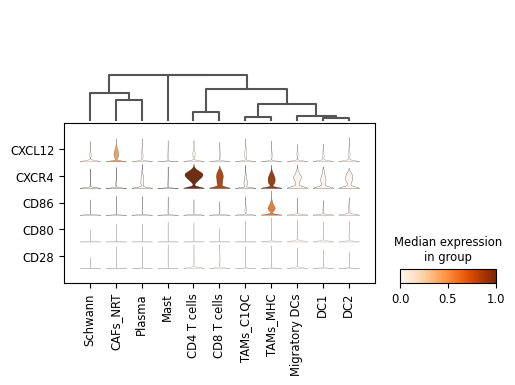

In [23]:
sc.pl.stacked_violin(
    plotting_107_all, var_names=['CXCL12','CXCR4','CD86','CD80','CD28'], groupby="cell_class_threshold", swap_axes=True, dendrogram=True,
    vmax=1, cmap = 'Oranges', save='Fig5e_CXCL12_CXCR4_signalling.pdf'
)

## Extended Data Fig. 2d: KRAS G12D and GNAS R844H, MH106_480

Originally made from `MH106_setseed_Jun25_filtered.h5ad`.

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


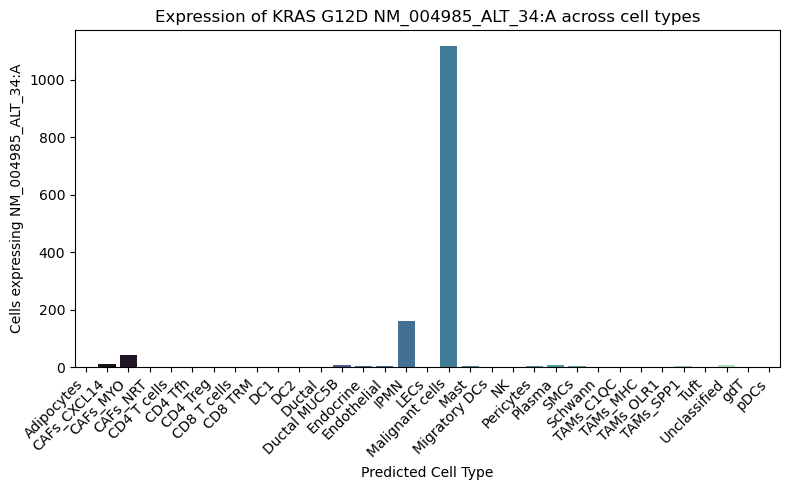

,cell_class_threshold,expressing_cell_count
0,CAFs_CXCL14,11
1,CAFs_MYO,42
2,CAFs_NRT,1
3,CD4 T cells,2
4,DC2,1
5,Ductal MUC5B,8
6,Endocrine,3
7,Endothelial,3
8,IPMN,161
9,Malignant cells,1116


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


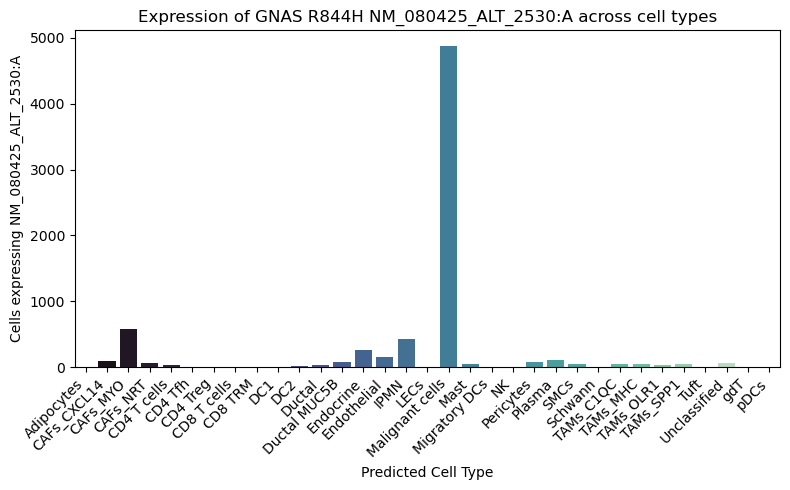

,cell_class_threshold,expressing_cell_count
0,CAFs_CXCL14,87
1,CAFs_MYO,584
2,CAFs_NRT,62
3,CD4 T cells,32
4,CD4 Tfh,2
5,CD4 Treg,2
6,CD8 T cells,7
7,CD8 TRM,2
8,DC1,8
9,DC2,18


In [20]:
def mutation_barplot(probe, title, name):
    assert probe in adata_106_480.var_names, f"{probe} is not in the MH106_480 object"
    expr = adata_106_480[:, probe].X
    expr = expr.toarray().flatten() if hasattr(expr, "toarray") else np.ravel(expr)
    df = adata_106_480.obs.copy()
    df["is_expressed"] = expr > 0
    summary_df = (
        df[df["is_expressed"]]
        .groupby("cell_class_threshold", observed=True)
        .size()
        .reset_index(name="expressing_cell_count")
    )
    plt.figure(figsize=(8, 5))
    sns.barplot(data=summary_df, x="cell_class_threshold", y="expressing_cell_count", palette="mako")
    plt.xticks(rotation=45, ha='right')
    plt.ylabel(f"Cells expressing {probe}")
    plt.xlabel("Predicted Cell Type")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURE_DIR, name), dpi=300)
    plt.show()
    return summary_df


display(mutation_barplot("NM_004985_ALT_34:A", "Expression of KRAS G12D NM_004985_ALT_34:A across cell types", "EDFig2d-1_MH106_G12D.pdf"))
display(mutation_barplot("NM_080425_ALT_2530:A", "Expression of GNAS R844H NM_080425_ALT_2530:A across cell types", "EDFig2d-2_MH106_GNAS_R844H.pdf"))

## Extended Data Fig. 5c–d: CAF clusters, MH106_480

Originally made from `MH106_setseed_Jun25_filtered.h5ad`. Genes in the final figure: Leiden, POSTN, KRT19, PDGFRA, C7, CXCL14.

~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


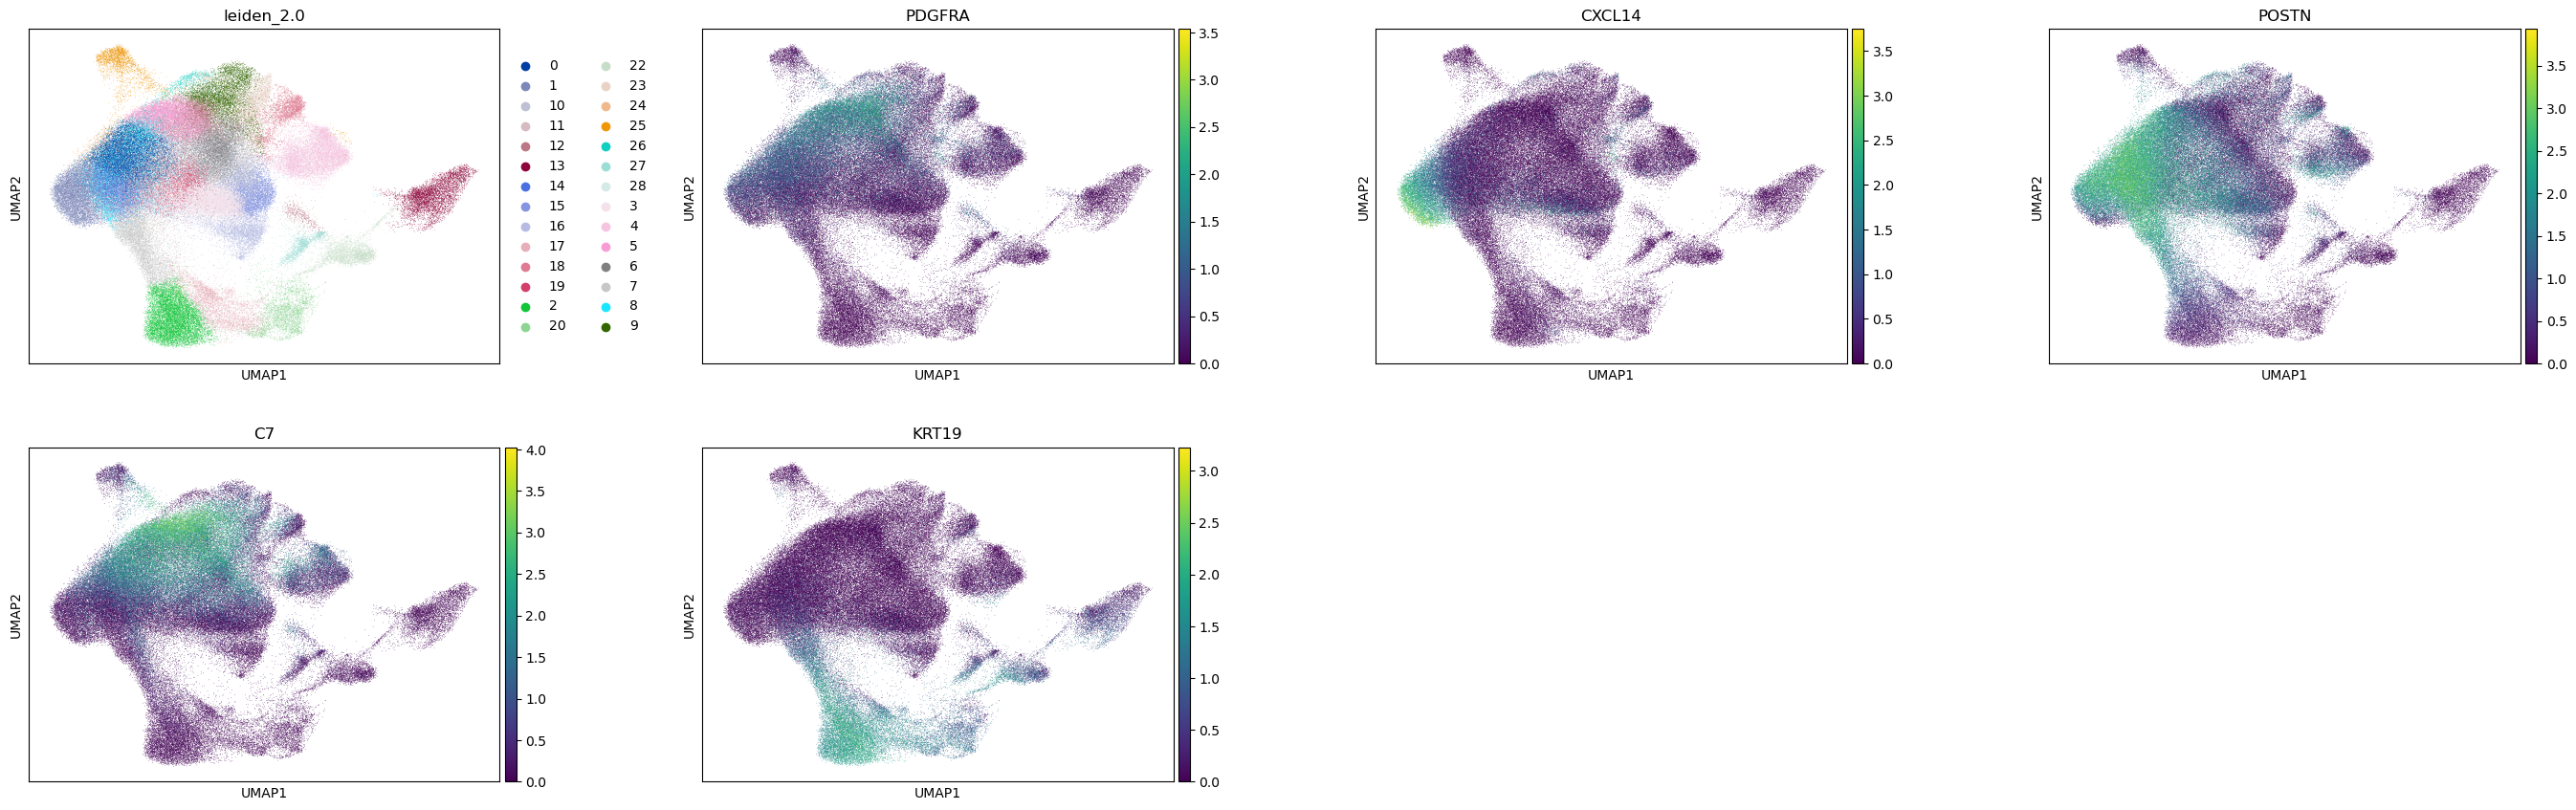

In [24]:
sc.pl.umap(adata_106_480, color=['leiden_2.0',"PDGFRA",'CXCL14','POSTN','C7','KRT19'], wspace = 0.3,
           save='_EDFig5c_CAFs_clustering_MH106.png'
          )

cell_class_threshold
CAFs_MYO           35253
Malignant cells    20629
CAFs_CXCL14        10016
CAFs_NRT            6053


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


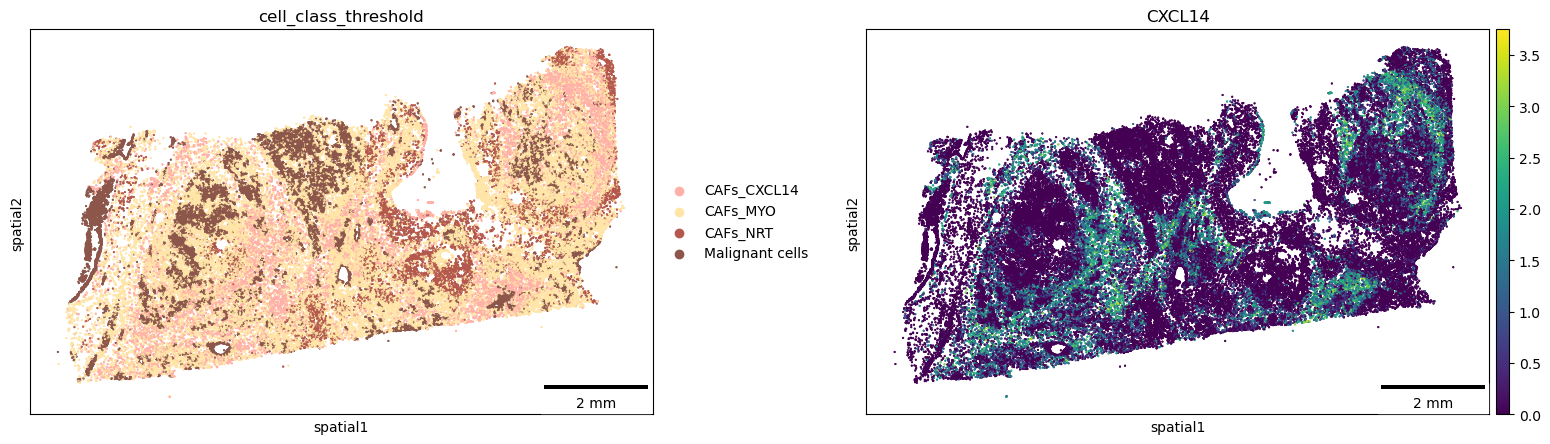

In [25]:
CAFs_106_480 = subset(adata_106_480, ['CAFs_MYO',"CAFs_CXCL14",'CAFs_NRT','Malignant cells'])
sq.pl.spatial_scatter(
    CAFs_106_480, shape=None, color=['cell_class_threshold','CXCL14'], size=1, library_id="spatial", figsize=(8, 5), wspace=0.2,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='EDFig5d_CAFs_CXCL14rep.png')

## Extended Data Fig. 8h-i Lymph node, MH104_480

In [40]:
lymphoid_104_480 = adata_104_480[adata_104_480.obs['cell_class_threshold'].isin(['B cells','FDCs','FRCs','TRCs'])].copy() 

In [41]:
lymphoid_104_480.uns['cell_class_threshold_colors']=['#ff7f0e',"#DD51AD","#00BFA0","#BBDA8F"]

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


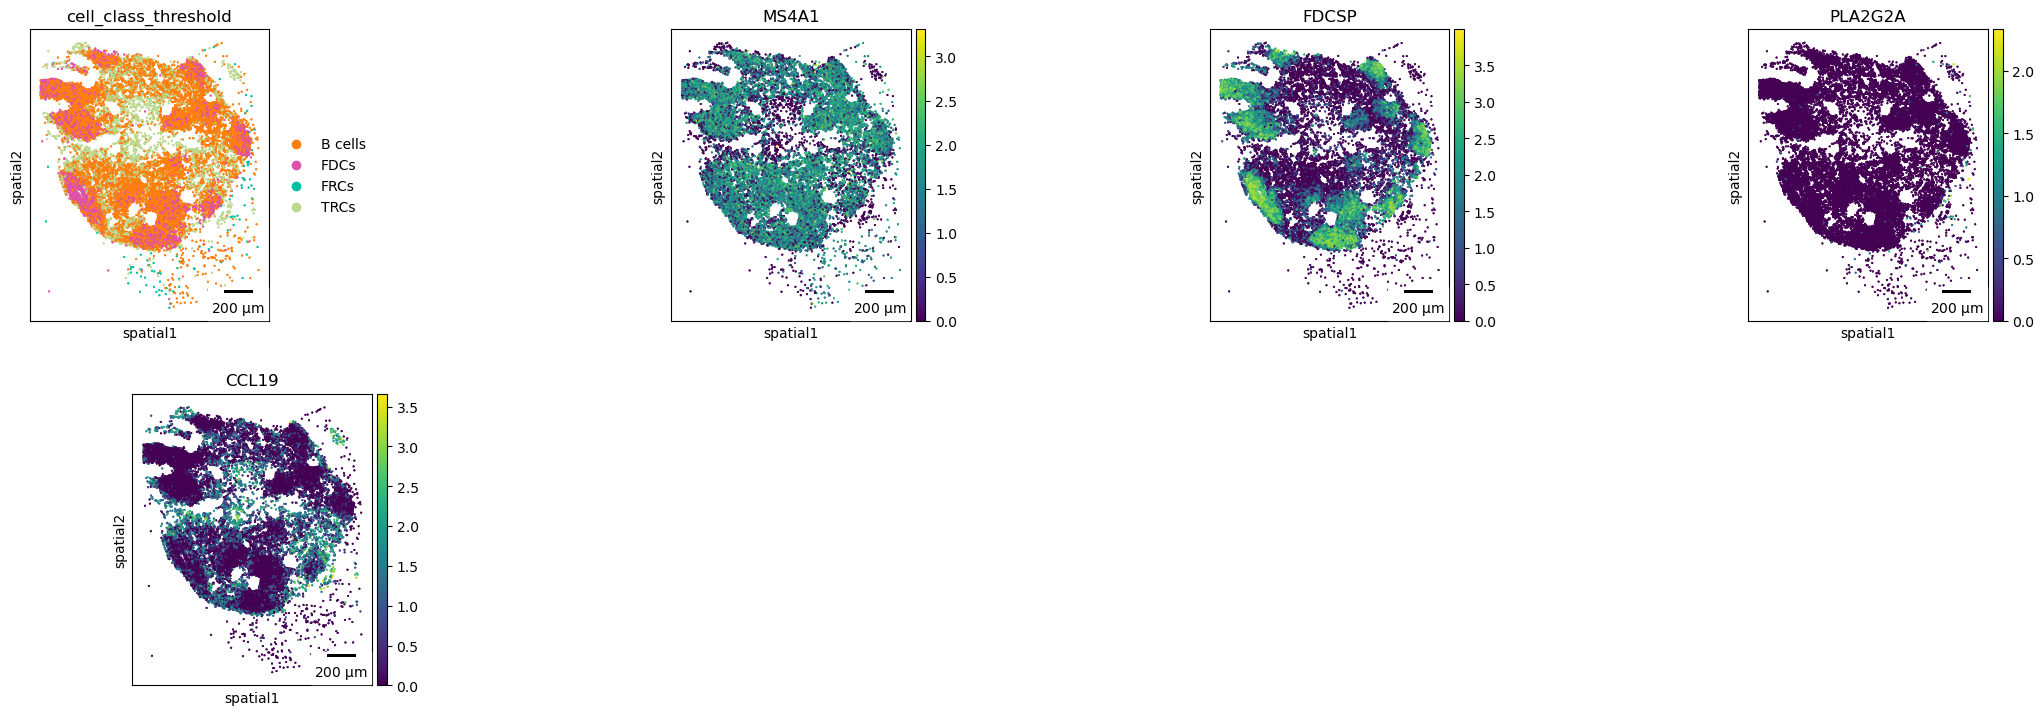

In [42]:
sq.pl.spatial_scatter(
    lymphoid_104_480, shape=None, color=['cell_class_threshold','MS4A1','FDCSP','PLA2G2A','CCL19'],
    size=1, library_id="spatial", figsize=(6, 4), wspace=0.1,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(7000, 0, 8500, 2000),
    save='EDFig8i_lymphnode.png'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


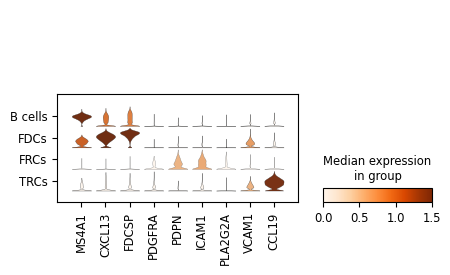

In [46]:
genes_anno = ['MS4A1','CXCL13','FDCSP','PDGFRA','PDPN','ICAM1','PLA2G2A','VCAM1','CCL19']
sc.pl.stacked_violin(
    lymphoid_104_480, genes_anno, groupby="cell_class_threshold", swap_axes=False, #dendrogram=True,
    vmax=1.5, 
    cmap = 'Oranges',
    save='LymphoidStromal_geneexpression.png'
)

## Saved figures

In [ ]:
print("\n".join(sorted(os.listdir(FIGURE_DIR))))